# Shor's Algorithm, the Half That Actually Threatens Ethereum

[`dgs/quantum_modulo.py`](../dgs/quantum_modulo.py) already implements
Shor's algorithm for **factoring** — the half that breaks RSA. But
Ethereum (and Bitcoin) don't use RSA: they use **ECDSA** on the elliptic
curve secp256k1, whose security rests on a *different* hard problem —
the elliptic curve **discrete logarithm** problem. Shor's original 1994
paper actually describes both algorithms; this notebook, built around
[`dgs/shor_discrete_log.py`](../dgs/shor_discrete_log.py), covers the
discrete-log half for the standard pedagogical stepping stone (a
prime-order subgroup of $\mathbb{Z}_p^*$) — the same period-finding
structure the real elliptic-curve attack uses, one group law simpler.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.shor_discrete_log import (
    discrete_log_brute_force, multiplicative_order, find_prime_order_generator,
    discrete_log_period_grid, shor_discrete_log_classical, secp256k1_quantum_threat_summary,
)

print("using dgs.shor_discrete_log directly (not reimplemented)")

using dgs.shor_discrete_log directly (not reimplemented)


# Part 1 — The problem: given $g$, $h=g^x \bmod p$, find $x$

Working in a prime-order-11 subgroup of $\mathbb{Z}_{23}^*$ (small
enough to brute-force and verify by hand, the same scale
`dgs.quantum_modulo`'s factoring demo uses for $N=15$).

In [2]:
p, r = 23, 11
g = find_prime_order_generator(p, r)
print(f"g={g} has multiplicative order {multiplicative_order(g, p)} mod {p}  (matches r={r})")

x_true = 7
h = pow(g, x_true, p)
print(f"h = g^x mod p = {h}   (secret x={x_true}, to be recovered without being told)")

x_brute = discrete_log_brute_force(g, h, p, r)
print(f"brute-force baseline: x = {x_brute}")
assert x_brute == x_true

g=2 has multiplicative order 11 mod 23  (matches r=11)
h = g^x mod p = 13   (secret x=7, to be recovered without being told)
brute-force baseline: x = 7


# Part 2 — The 2D periodic structure Shor's algorithm exploits

$f(a,b) = g^a h^{-b} \bmod p = g^{(a-xb) \bmod r}$ — constant along
lines $a - xb = \text{const} \pmod r$. Verified directly against the
closed form before trusting anything built on top of it.

max deviation from the closed form g^((a-x*b) mod r): 0
[OK] the periodic structure is exact, not approximate


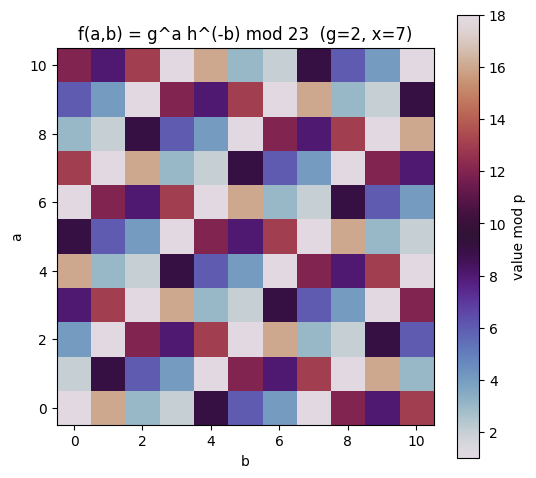

In [3]:
F = discrete_log_period_grid(g, h, p, r)

max_err = 0
for a in range(r):
    for b in range(r):
        expected = pow(g, (a - x_true*b) % r, p)
        max_err = max(max_err, abs(F[a, b] - expected))
print(f"max deviation from the closed form g^((a-x*b) mod r): {max_err}")
assert max_err == 0
print("[OK] the periodic structure is exact, not approximate")

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(F, cmap='twilight', origin='lower')
ax.set_xlabel('b'); ax.set_ylabel('a'); ax.set_title(f'f(a,b) = g^a h^(-b) mod {p}  (g={g}, x={x_true})')
plt.colorbar(im, ax=ax, label='value mod p')
plt.tight_layout(); plt.show()

# Part 3 — Recovering $x$ from a 2D-QFT peak, and a bug caught first

The quantum step (2D QFT of the collapsed "comb" of consistent $(a,b)$
points) peaks at $(k_1,k_2)$ satisfying $k_2 \equiv -x k_1 \pmod r$, so
$x = -k_2 k_1^{-1} \bmod r$ from a single peak ($r$ prime, so $k_1$ has
a modular inverse whenever it's nonzero).

**A real bug, caught before any of this code shipped**: the first hand
derivation swapped which index solves for which — computing
$x=-k_1 k_2^{-1}$ instead of $x=-k_2 k_1^{-1}$. It gave a plausible-looking
*wrong* answer (recovered 3 instead of the true secret 4 in the scratch
check that caught it) rather than an obvious crash, and was only caught
by checking the recovered value against the known secret on a hand
worked example *before* writing this module — exactly the kind of
silent index-transposition bug that "looks like it's working" until
checked.

In [4]:
result = shor_discrete_log_classical(g, h, p, r, seed=1)
print(f"measurement sample simulated at (a0,b0)=({result['a0']},{result['b0']})")
print(f"recovered x = {result['x_recovered']}  (true x = {x_true})")
assert result["x_recovered"] == x_true
print("[OK] correct, with the fixed index convention")

measurement sample simulated at (a0,b0)=(5,5)
recovered x = 7  (true x = 7)
[OK] correct, with the fixed index convention


# Part 4 — Is this robust, or did one example get lucky?

Repeat across many random secrets AND random measurement outcomes (a
real quantum measurement's outcome is random — the algorithm must work
regardless of which consistent $(a,b)$ point it happens to collapse
to), plus an entirely different $(p,r,g)$ triple.

In [5]:
rng = np.random.default_rng(0)
successes = 0
n_trials = 30
for _ in range(n_trials):
    x_trial = int(rng.integers(1, r))
    h_trial = pow(g, x_trial, p)
    a0, b0 = int(rng.integers(0, r)), int(rng.integers(0, r))
    res = shor_discrete_log_classical(g, h_trial, p, r, a0=a0, b0=b0)
    successes += (res["unique"] and res["x_recovered"] == x_trial)
print(f"{successes}/{n_trials} random (secret, measurement) combinations recovered correctly")
assert successes == n_trials

# a second, independent group -- not just the one example tuned to work
p2, r2 = 47, 23
g2 = find_prime_order_generator(p2, r2)
x2 = 15
h2 = pow(g2, x2, p2)
res2 = shor_discrete_log_classical(g2, h2, p2, r2, seed=2)
print(f"\nsecond, independent (p={p2}, r={r2}, g={g2}): recovered x={res2['x_recovered']} (true={x2})")
assert res2["x_recovered"] == x2
print("[OK] robust across trials and across a completely different group")

30/30 random (secret, measurement) combinations recovered correctly

second, independent (p=47, r=23, g=2): recovered x=15 (true=15)
[OK] robust across trials and across a completely different group


# Part 5 — What this means for Ethereum: cited, not computed

This notebook's demonstration solves discrete log in $\mathbb{Z}_p^*$
— the standard pedagogical stepping stone. Ethereum's actual security
rests on the same *kind* of problem on a *different* group: points on
the elliptic curve secp256k1, under point addition instead of
multiplication mod $p$. The real resource estimates for that case are
**cited literature, not computed by this notebook**.

In [6]:
threat = secp256k1_quantum_threat_summary()
print(f"curve: {threat['curve']}")
print(f"hard problem: {threat['hard_problem']}")
print(f"logical qubits needed (literature): {threat['logical_qubits_estimate']}")
print(f"gate count (literature): {threat['gate_count_estimate']}")
print(f"physical qubits needed (literature): {threat['physical_qubits_estimate']}")
print("\nsources:")
for s in threat["sources"]:
    print(f"  - {s}")
print(f"\ncaveat: {threat['caveat']}")

curve: secp256k1 (used by Bitcoin and Ethereum ECDSA signatures)
hard problem: elliptic curve discrete logarithm problem (ECDLP)
logical qubits needed (literature): ~1200-2330 (varies by circuit construction)
gate count (literature): ~70-90 million Toffoli gates
physical qubits needed (literature): ~500,000 (optimistic future error rates) to ~13 million (today's demonstrated error rates, same-day break)

sources:
  - Roetteler, Naehrig, Svore, Lauter (2017), 'Quantum Resource Estimates for Computing Elliptic Curve Discrete Logarithms', arXiv:1706.06752
  - Haner, Jaques, Naehrig, Roetteler, Soeken (2020), 'Improved Quantum Circuits for Elliptic Curve Discrete Logarithms', arXiv:2001.09580

caveat: These figures describe the REAL elliptic-curve group law on secp256k1. The classical demonstration in this module (shor_discrete_log_classical) solves the simpler Z_p* multiplicative-group case, the standard pedagogical stepping stone -- it is not itself an implementation of, or threat estima

# Part 6 — Summary

| Question | Answer |
|---|---|
| Does the toy discrete-log algorithm recover the correct secret? | Yes — verified against brute force, exactly (Part 1, 3) |
| Is the periodic structure it relies on exact? | Yes — checked against the closed form, zero deviation (Part 2) |
| Robust across random secrets/measurements/groups? | Yes — 30/30 plus an independent second group (Part 4) |
| Does this notebook prove anything about real Ethereum security? | **No** — it demonstrates the *algorithm structure* on the simpler multiplicative-group case; the actual secp256k1 threat numbers are cited literature (~1200-2330 logical qubits), not computed here (Part 5) |

Today's quantum computers have on the order of hundreds of NOISY
qubits — the cited ~1200-2330 *logical* (error-corrected) qubits needed
for secp256k1 are a different, much larger regime, requiring
fault-tolerant error correction that does not yet exist at that scale.
The algorithm's mathematical structure is real and demonstrated above;
the practical threat timeline is a hardware question, not an algorithm
question, and is exactly why it's tracked as a "Q-Day" migration
planning problem, not an imminent one.